# Message Intelligence System

# Part A: Probability & Conceptual Foundation

### Question: 1 What is Conditional Probability?
Conditional probability is the probability of event **A happening given that event B has already happened**:

$$P(A \mid B) = \frac{P(A \cap B)}{P(B)}, \quad P(B) > 0$$

*Example:* P(Spam | message has a URL) = (spam messages with URL) / (all messages with URL). Knowing the message has a URL changes our belief about it being spam.

### Question: 2 Bayes' Theorem and why it matters in classification
$$P(C \mid X) = \frac{P(X \mid C)\, P(C)}{P(X)}$$

- **P(C)** = prior (how common spam is overall), **P(X | C)** = likelihood (how typical these features are for class C), **P(C | X)** = posterior (what we want).
- It lets us flip "how likely are these features *given* spam" (easy to learn from data) into "how likely is spam *given* these features" (what we need to decide). Classification = choose the class with the highest posterior.

### Question: 3 Assumptions of Naive Bayes
1. **Conditional independence:** given the class, all features are independent: $P(x_1,\dots,x_n \mid C)=\prod_i P(x_i \mid C)$.
2. **Equal importance** of every feature (no feature weighting).
3. For **GaussianNB**: each numeric feature is **normally distributed** within each class.
4. Features are assumed to be sufficiently informative and training data representative of the real data.


### Question: 4 Working principle
**K-Nearest Neighbors (KNN):** A *lazy* learner it stores the training data. For a new message it computes the distance to every training point, picks the **K closest**, and takes a **majority vote** of their labels. Needs **feature scaling** because it uses distance.

**Support Vector Machine (SVM):** Finds the **hyperplane that separates the two classes with the maximum margin**. Only the points closest to the boundary (**support vectors**) define it. Soft margin (parameter **C**) allows some mistakes; **kernels** (RBF, polynomial) let SVM draw non-linear boundaries by implicitly mapping data to a higher dimension.

### Question: 5 Distance-based vs Probabilistic vs Margin-based

| Aspect | Distance-based (KNN) | Probabilistic (Naive Bayes) | Margin-based (SVM) |
|---|---|---|---|
| Core idea | Similar points have same label | Use Bayes' theorem + class probabilities | Maximise gap between classes |
| Training | None (lazy) | Very fast (count / mean, variance) | Slower (optimisation) |
| Prediction | Slow (distance to all points) | Very fast | Fast |
| Needs scaling | Yes | Not strictly | Yes |
| Output | Vote ratio | True class probabilities | Distance from boundary (score) |
| Interpretability | Easy idea, no model | High (probabilities) | Medium (linear) / low (kernel) |
| Weakness | Noise, high dimensions, slow | Independence assumption | Tuning C/gamma, no native probability |

# Part B: Dataset Understanding & Preparation

In [37]:
import warnings; warnings.filterwarnings("ignore")
import os, json, re, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_curve, auc, precision_recall_curve)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
os.makedirs("images", exist_ok=True); os.makedirs("models", exist_ok=True)

def savefig(name):
    plt.tight_layout(); plt.savefig(f"images/{name}.png", dpi=130, bbox_inches="tight"); plt.show()

df = pd.read_excel("data/Message_Intelligence_Dataset_5200.xlsx")
print("Shape:", df.shape)
df.head()

Shape: (5200, 16)


,message_id,message_text,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,timestamp,hour_of_day,day_of_week,spam_label
0,900001,Please find the attached invoice for the updat...,99,11,1,4,0,0,1,56.6,500.0,6.0,2025-11-24 02:00:00,2,0,0
1,900002,Let's catch up tomorrow regarding the timeline...,73,12,0,0,0,0,0,16.6,207.0,0.0,2025-12-17 21:00:00,21,2,0
2,900003,Can you send the report by end of day? next Mo...,67,13,0,0,0,0,1,25.7,418.0,6.0,2025-11-15 13:00:00,13,5,0
3,900004,Can you send the report by end of day? 10:30 A...,64,13,0,4,0,0,1,48.8,276.0,5.0,2025-12-17 23:00:00,23,2,0
4,900005,Could you review the document and share feedba...,84,14,0,0,0,0,1,33.0,683.0,7.0,2025-11-29 11:00:00,11,5,0


In [38]:
df.info()
print()
print("Missing values per column:\n", df.isna().sum()[df.isna().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass balance (0=Legit, 1=Spam):\n", df["spam_label"].value_counts())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   message_id               5200 non-null   int64         
 1   message_text             5200 non-null   object        
 2   message_length           5200 non-null   int64         
 3   word_count               5200 non-null   int64         
 4   num_urls                 5200 non-null   int64         
 5   num_digits               5200 non-null   int64         
 6   num_special_chars        5200 non-null   int64         
 7   spam_keyword_score       5200 non-null   int64         
 8   legit_keyword_score      5200 non-null   int64         
 9   sender_activity_score    5094 non-null   float64       
 10  sender_account_age_days  5087 non-null   float64       
 11  messages_sent_last_24h   5038 non-null   float64       
 12  timestamp                5200 non-

,count,mean,min,25%,50%,75%,max,std
message_id,5200.0,902600.5,900001.0,901300.75,902600.5,903900.25,905200.0,1501.255031
message_length,5200.0,75.035962,32.0,67.0,74.0,81.0,122.0,12.455377
word_count,5200.0,11.457308,5.0,10.0,11.0,13.0,16.0,1.609056
num_urls,5200.0,0.206538,0.0,0.0,0.0,0.0,1.0,0.40486
num_digits,5200.0,1.681346,0.0,0.0,0.0,4.0,9.0,2.415846
num_special_chars,5200.0,0.243654,0.0,0.0,0.0,0.0,2.0,0.545363
spam_keyword_score,5200.0,0.246346,0.0,0.0,0.0,0.0,3.0,0.676798
legit_keyword_score,5200.0,0.817692,0.0,0.0,1.0,1.0,2.0,0.556687
sender_activity_score,5094.0,54.836317,5.0,43.1,54.8,66.6,100.0,17.697943
sender_account_age_days,5087.0,296.671909,2.0,148.0,275.0,410.5,1500.0,191.748754


### Task 6 Identify input features and target variable

In [39]:
TARGET = "spam_label"
FEATURES_ALL = ["message_length", "word_count", "num_urls", "num_digits", "num_special_chars",
                "spam_keyword_score", "legit_keyword_score",
                "sender_activity_score", "sender_account_age_days", "messages_sent_last_24h",
                "hour_of_day", "day_of_week"]
FEATURES = [f for f in FEATURES_ALL if f != "num_special_chars"]
X = df[FEATURES]; y = df[TARGET]
print("X shape:", X.shape, "| y shape:", y.shape, "| #features:", len(FEATURES))

X shape: (5200, 11) | y shape: (5200,) | #features: 11


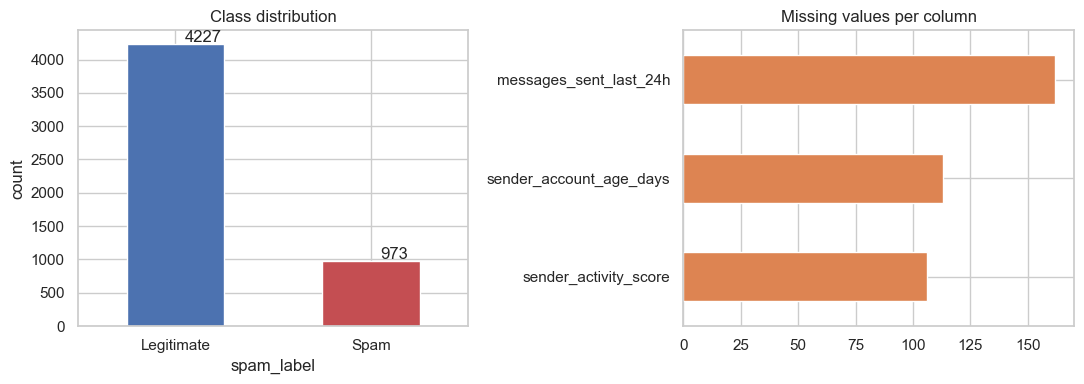

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
y.value_counts().rename({0: "Legitimate", 1: "Spam"}).plot(kind="bar", ax=ax[0], color=["#4C72B0", "#C44E52"])
ax[0].set_title("Class distribution"); ax[0].set_ylabel("count"); ax[0].tick_params(axis="x", rotation=0)
for p in ax[0].patches: ax[0].annotate(int(p.get_height()), (p.get_x()+0.3, p.get_height()+40))
df[FEATURES_ALL + [TARGET]].isna().sum().loc[lambda s: s > 0].plot(kind="barh", ax=ax[1], color="#DD8452")
ax[1].set_title("Missing values per column")
savefig("01_class_and_missing")

*Interpretation:* The data is **imbalanced** (~81% legitimate, ~19% spam), so **accuracy alone is misleading** we must also look at precision, recall and F1. Three sender columns have ~2-3% missing values, which we will impute.

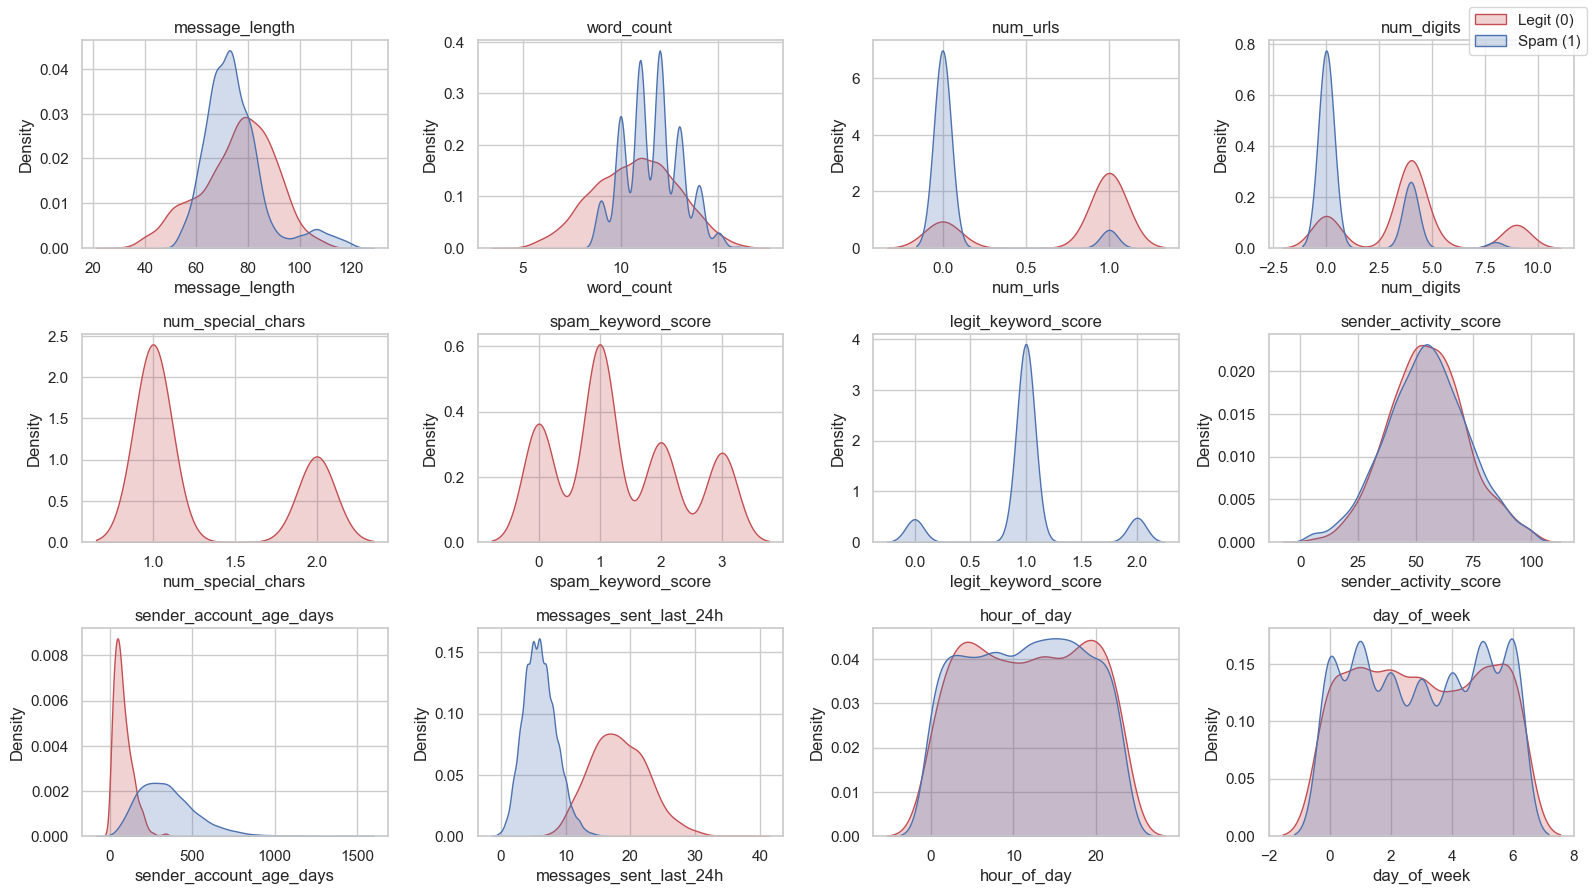

In [41]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for a, f in zip(axes.ravel(), FEATURES_ALL):
    sns.kdeplot(data=df, x=f, hue=TARGET, common_norm=False, fill=True, ax=a, palette=["#4C72B0", "#C44E52"], warn_singular=False)
    a.set_title(f); a.legend_.remove() if a.legend_ else None
fig.legend(["Legit (0)", "Spam (1)"], loc="upper right")
savefig("02_feature_distributions")

*Interpretation:* `spam_keyword_score`, `legit_keyword_score`, `num_special_chars`, `num_urls`, `num_digits`, `messages_sent_last_24h` and `sender_account_age_days` clearly differ between classes. `hour_of_day`, `day_of_week`, `message_length` look almost identical → weak features.

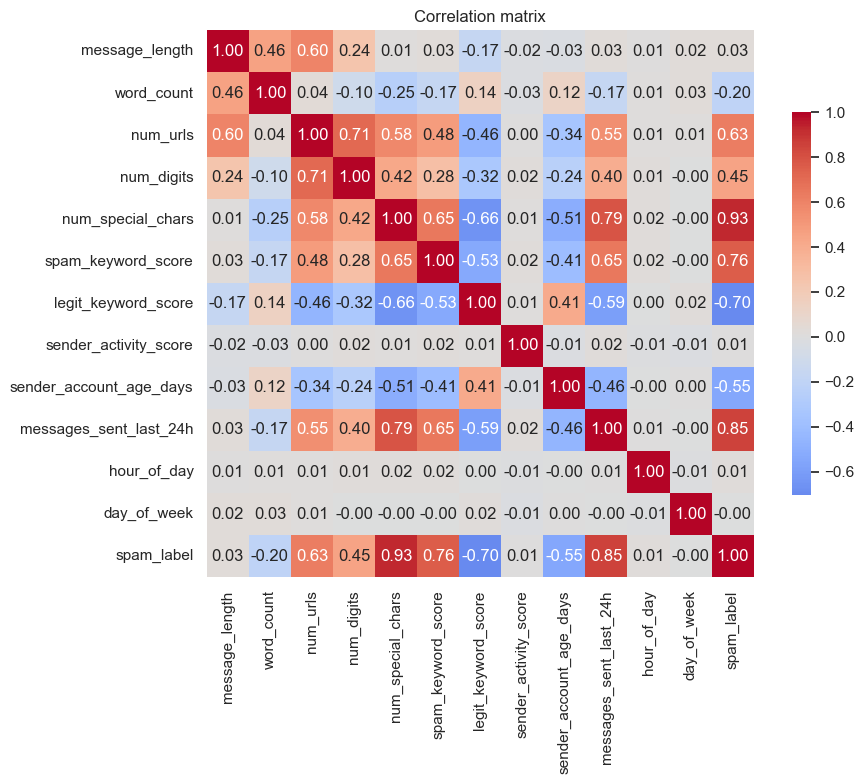

In [42]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[FEATURES_ALL + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Correlation matrix")
savefig("03_correlation")

*Interpretation:* `message_length` and `word_count` are correlated with each other (violates the Naive Bayes independence assumption). Keyword scores, URL count and special characters have the strongest correlation with `spam_label`.

### Data-leakage check
Before modelling we check whether any single feature separates the classes perfectly.

In [43]:
print(pd.crosstab(df["num_special_chars"] > 0, df[TARGET], rownames=["num_special_chars > 0"], colnames=["spam_label"]))
print()
print(pd.crosstab(df["spam_keyword_score"] > 0, df[TARGET], rownames=["spam_keyword_score > 0"], colnames=["spam_label"]))
print()
print(pd.crosstab(df["legit_keyword_score"] > 0, df[TARGET], rownames=["legit_keyword_score > 0"], colnames=["spam_label"]))

spam_label                0    1
num_special_chars > 0           
False                  4227    0
True                      0  973

spam_label                 0    1
spam_keyword_score > 0           
False                   4227  228
True                       0  745

spam_label                  0    1
legit_keyword_score > 0           
False                     393  973
True                     3834    0


*Finding:* **`num_special_chars > 0` happens in 100% of spam and 0% of legitimate messages** this single feature gives a perfect classifier (in this synthetic dataset it counts the `!` character that only spam templates contain). `spam_keyword_score > 0` is also spam-only, and `legit_keyword_score > 0` is legit-only.

**Decision:** If we keep `num_special_chars`, every model scores 100% and the comparison tasks (K tuning, margins, misclassification, precision vs recall) become meaningless. So we **exclude `num_special_chars` from the model inputs (11 features remain)** and we additionally run a "hard mode" test without keyword scores in Part G. The all-features result is still reported below (Scenario A) for completeness.

### Task 8 Train/Test split
80% train / 20% test, **stratified** so both sets keep the same spam ratio. We put imputer + scaler inside a `Pipeline`, so they learn only from the training set.

In [44]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Spam %% train: %.2f | test: %.2f" % (y_train.mean()*100, y_test.mean()*100))

def make_pipe(model):
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler()),
                     ("model", model)])

prep = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]).fit(X_train)
Xtr_s = pd.DataFrame(prep.transform(X_train), columns=FEATURES)
Xte_s = pd.DataFrame(prep.transform(X_test), columns=FEATURES)
print("\nMissing after imputation:", int(Xtr_s.isna().sum().sum()))
Xtr_s.describe().loc[["mean", "std"]].round(2)

Train: (4160, 11) | Test: (1040, 11)
Spam % train: 18.70 | test: 18.75

Missing after imputation: 0


,message_length,word_count,num_urls,num_digits,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,hour_of_day,day_of_week
mean,0.0,-0.0,0.0,0.0,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


*Interpretation:* After scaling, every feature has mean ≈ 0 and std ≈ 1, so all features contribute fairly to distance and margin calculations. The class ratio is preserved in both splits.

In [45]:
XA_tr, XA_te, _, _ = train_test_split(df[FEATURES_ALL], y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
rows = []
for n, m in {"KNN (K=5)": KNeighborsClassifier(5), "SVM (RBF)": SVC(), "Naive Bayes": GaussianNB()}.items():
    p = make_pipe(m).fit(XA_tr, y_train).predict(XA_te)
    rows.append({"Model": n, "Accuracy": accuracy_score(y_test, p), "Precision": precision_score(y_test, p), "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p)})
print("Scenario A with ALL 12 features (perfect separator included):")
pd.DataFrame(rows).set_index("Model").round(4)

Scenario A with ALL 12 features (perfect separator included):


,Accuracy,Precision,Recall,F1
Model,,,,
KNN (K=5),1.0,1.0,1.0,1.0
SVM (RBF),1.0,1.0,1.0,1.0
Naive Bayes,1.0,1.0,1.0,1.0


*Interpretation:* With the perfect separator all models reach ~100% — nothing to compare. From here on we use the **11 leakage-safe features**.

# Part C: Baseline Model K-Nearest Neighbors

### Task 9 Implement KNN

In [46]:
def evaluate(model, name, Xte=X_test, yte=y_test):
    pred = model.predict(Xte)
    return {"Model": name,
            "Accuracy": accuracy_score(yte, pred),
            "Precision": precision_score(yte, pred),
            "Recall": recall_score(yte, pred),
            "F1": f1_score(yte, pred)}

knn_base = make_pipe(KNeighborsClassifier(n_neighbors=5)).fit(X_train, y_train)
print("KNN (K=5, euclidean) baseline on test set:")
pd.DataFrame([evaluate(knn_base, "KNN K=5")]).round(4)

KNN (K=5, euclidean) baseline on test set:


,Model,Accuracy,Precision,Recall,F1
0,KNN K=5,0.9971,1.0,0.9846,0.9922


### Task 10 Experiment with different values of K
We try K = 1…31. **K is chosen with 5-fold cross-validation on the training set** (not the test set — that would be cheating). Small K → low bias / high variance (overfits noise); large K → smooth boundary, can underfit.

In [47]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
ks = list(range(1, 32, 2))
rows = []
for k in ks:
    pipe = make_pipe(KNeighborsClassifier(n_neighbors=k))
    cv_f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1").mean()
    pipe.fit(X_train, y_train)
    rows.append({"K": k, "Train F1": f1_score(y_train, pipe.predict(X_train)),
                 "CV F1": cv_f1, "Test F1": f1_score(y_test, pipe.predict(X_test)),
                 "Test Accuracy": accuracy_score(y_test, pipe.predict(X_test))})
k_results = pd.DataFrame(rows)

top = k_results[k_results["CV F1"] >= k_results["CV F1"].max() - 0.001]
best_k = int(top[top["K"] >= 3]["K"].min()) if (top["K"] >= 3).any() else int(top["K"].min())
print("Best K by cross-validated F1:", best_k)
k_results.round(4)

Best K by cross-validated F1: 3


,K,Train F1,CV F1,Test F1,Test Accuracy
0,1,1.0000,0.9961,0.9974,0.9990
1,3,0.9974,0.9955,0.9974,0.9990
2,5,0.9981,0.9955,0.9922,0.9971
3,7,0.9981,0.9955,0.9922,0.9971
4,9,0.9968,0.9955,0.9922,0.9971
5,11,0.9974,0.9935,0.9896,0.9962
6,13,0.9974,0.9929,0.9896,0.9962
7,15,0.9968,0.9929,0.9870,0.9952
8,17,0.9961,0.9916,0.9896,0.9962
9,19,0.9961,0.9922,0.9870,0.9952


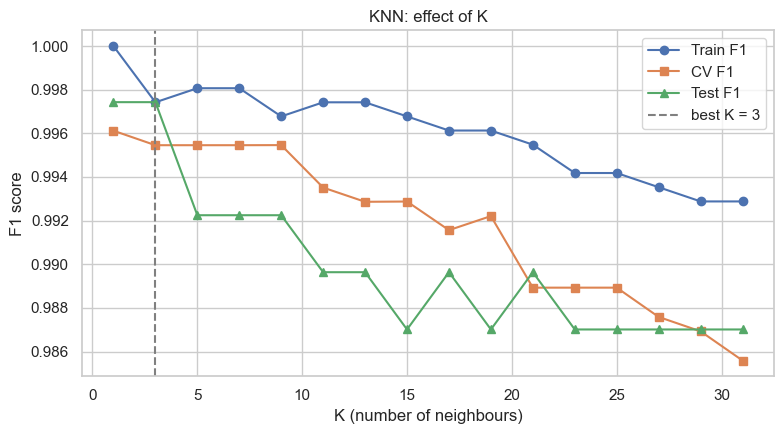

In [48]:
plt.figure(figsize=(8, 4.5))
plt.plot(k_results["K"], k_results["Train F1"], "o-", label="Train F1")
plt.plot(k_results["K"], k_results["CV F1"], "s-", label="CV F1")
plt.plot(k_results["K"], k_results["Test F1"], "^-", label="Test F1")
plt.axvline(best_k, color="grey", ls="--", label=f"best K = {best_k}")
plt.xlabel("K (number of neighbours)"); plt.ylabel("F1 score"); plt.title("KNN: effect of K"); plt.legend()
savefig("04_knn_k_vs_f1")

*Interpretation:* At **K=1** the train F1 is perfect (it memorises the training data) but CV/test F1 is lower → overfitting. As K grows, train and CV/test scores come closer (better generalisation). Very large K starts to blur the spam class (the minority class). We pick the K with the best **CV F1**.

### Task 11 How do distance metrics affect predictions?

,Accuracy,Precision,Recall,F1
Distance metric,,,,
euclidean (p=2),0.9990,1.0,0.9949,0.9974
manhattan (p=1),0.9990,1.0,0.9949,0.9974
chebyshev,0.9962,1.0,0.9795,0.9896
cosine,0.9981,1.0,0.9897,0.9948


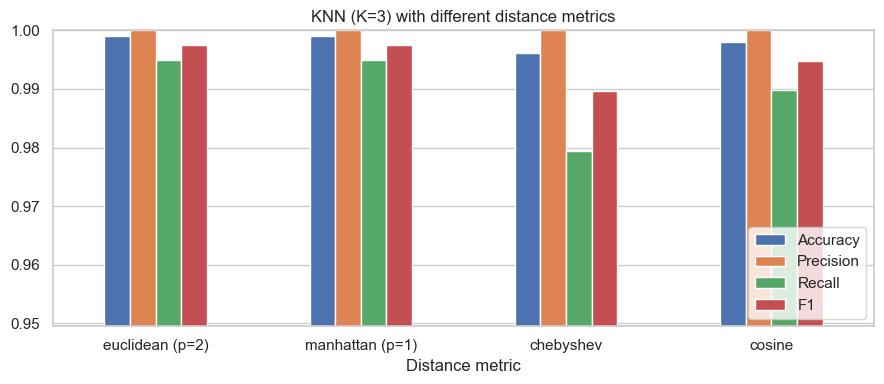

KNN WITHOUT scaling : {'Model': 'no scaling', 'Accuracy': 0.9701923076923077, 'Precision': 0.9555555555555556, 'Recall': 0.882051282051282, 'F1': 0.9173333333333333}
KNN WITH scaling    : {'Model': 'scaled', 'Accuracy': 0.9990384615384615, 'Precision': 1.0, 'Recall': 0.9948717948717949, 'F1': 0.9974293059125964}


In [49]:
metrics_cfg = {"euclidean (p=2)": dict(metric="minkowski", p=2),
               "manhattan (p=1)": dict(metric="minkowski", p=1),
               "chebyshev": dict(metric="chebyshev"),
               "cosine": dict(metric="cosine", algorithm="brute")}
rows = []
for name, cfg in metrics_cfg.items():
    m = make_pipe(KNeighborsClassifier(n_neighbors=best_k, **cfg)).fit(X_train, y_train)
    rows.append(evaluate(m, name))
dist_df = pd.DataFrame(rows).rename(columns={"Model": "Distance metric"}).set_index("Distance metric")
display(dist_df.round(4))
dist_df.plot(kind="bar", figsize=(9, 4), ylim=(dist_df.values.min()-0.03, 1.0)); plt.xticks(rotation=0)
plt.title(f"KNN (K={best_k}) with different distance metrics"); plt.legend(loc="lower right")
savefig("05_knn_distance_metrics")

raw = Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", KNeighborsClassifier(n_neighbors=best_k))]).fit(X_train, y_train)
print("KNN WITHOUT scaling :", evaluate(raw, "no scaling"))
print("KNN WITH scaling    :", evaluate(make_pipe(KNeighborsClassifier(n_neighbors=best_k)).fit(X_train, y_train), "scaled"))

*Interpretation:* The metric changes how 'closeness' is measured: **Euclidean** squares differences (sensitive to one big difference), **Manhattan** sums absolute differences (more robust to outliers), **Chebyshev** only looks at the single largest difference, **Cosine** looks at the angle, ignoring magnitude. **Result:** Euclidean and Manhattan are the best (F1 ≈ 0.997); Cosine is slightly lower; Chebyshev is worst (recall drops) because it ignores all but one feature's difference. The scaling test proves distance-based models need scaled features (F1 ≈ 0.92 without scaling vs ≈ 0.997 with scaling).

### Task 12 Cases where KNN misclassifies messages

In [50]:
knn_best = make_pipe(KNeighborsClassifier(n_neighbors=best_k)).fit(X_train, y_train)
pred_knn = knn_best.predict(X_test)
wrong = X_test.copy(); wrong["message_text"] = df.loc[X_test.index, "message_text"]
wrong["actual"] = y_test; wrong["predicted"] = pred_knn
wrong = wrong[wrong.actual != wrong.predicted]
print(f"Total misclassified: {len(wrong)} of {len(X_test)}")
print("False Positives (legit predicted as spam):", int(((wrong.actual==0)&(wrong.predicted==1)).sum()))
print("False Negatives (spam predicted as legit):", int(((wrong.actual==1)&(wrong.predicted==0)).sum()))
wrong[["message_text", "spam_keyword_score", "legit_keyword_score", "num_urls", "num_digits",
       "sender_account_age_days", "messages_sent_last_24h", "actual", "predicted"]].head(15)

Total misclassified: 1 of 1040
False Positives (legit predicted as spam): 0
False Negatives (spam predicted as legit): 1


,message_text,spam_keyword_score,legit_keyword_score,num_urls,num_digits,sender_account_age_days,messages_sent_last_24h,actual,predicted
905,You are eligible for a refund of a brand new p...,0,0,0,0,18.0,NaN,1,0


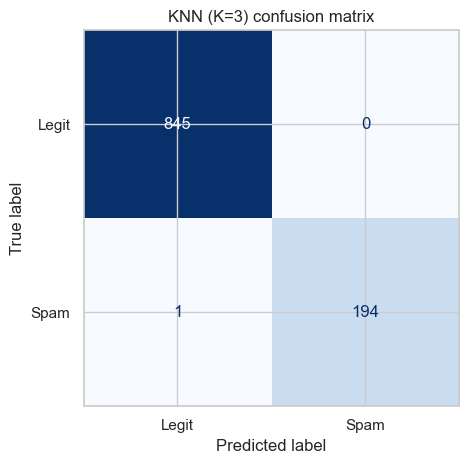

Average feature values: misclassified messages vs the typical message of that class


,typical_class_0,typical_class_1,misclassified_actual_1
message_length,75.09,74.03,62.0
word_count,11.62,10.63,13.0
num_urls,0.10,0.72,0.0
num_digits,1.23,4.03,0.0
spam_keyword_score,0.00,1.22,0.0
legit_keyword_score,0.99,0.00,0.0
sender_activity_score,54.17,59.19,91.5
sender_account_age_days,357.32,75.81,18.0
messages_sent_last_24h,5.95,18.63,NaN
hour_of_day,11.46,11.90,22.0


In [51]:
cm = confusion_matrix(y_test, pred_knn)
ConfusionMatrixDisplay(cm, display_labels=["Legit", "Spam"]).plot(cmap="Blues", colorbar=False)
plt.title(f"KNN (K={best_k}) confusion matrix"); savefig("06_knn_confusion")
if len(wrong):
    print("Average feature values: misclassified messages vs the typical message of that class")
    typical = X_test.groupby(y_test).mean().T.add_prefix("typical_class_")
    wr = wrong.groupby("actual")[FEATURES].mean().T.add_prefix("misclassified_actual_")
    display(pd.concat([typical, wr], axis=1).round(2))

In [52]:
knn31 = make_pipe(KNeighborsClassifier(n_neighbors=31)).fit(X_train, y_train)
p31 = knn31.predict(X_test)
w31 = X_test.copy(); w31["message_text"] = df.loc[X_test.index, "message_text"].str[:60]; w31["actual"] = y_test; w31["predicted"] = p31
w31 = w31[w31.actual != w31.predicted]
print(f"K=31 misclassified: {len(w31)} (FP={int(((w31.actual==0)&(w31.predicted==1)).sum())}, FN={int(((w31.actual==1)&(w31.predicted==0)).sum())})")
w31[["message_text", "spam_keyword_score", "legit_keyword_score", "num_urls", "num_digits", "sender_account_age_days", "messages_sent_last_24h", "actual", "predicted"]]

K=31 misclassified: 5 (FP=0, FN=5)


,message_text,spam_keyword_score,legit_keyword_score,num_urls,num_digits,sender_account_age_days,messages_sent_last_24h,actual,predicted
4750,Get rich quick with this simple trick a brand ...,0,0,1,4,NaN,NaN,1,0
1805,Act fast! Your account will be suspended unles...,0,0,1,9,NaN,NaN,1,0
905,You are eligible for a refund of a brand new p...,0,0,0,0,18.0,NaN,1,0
2636,"Earn money from home instantly ₹50,000 now!",0,0,0,5,28.0,NaN,1,0
4676,"You are eligible for a refund of ₹50,000 befor...",0,0,0,5,41.0,14.0,1,0


*Interpretation (typical reasons KNN fails):*
- **Borderline messages:** spam with *no* spam keyword, no URL and no digits (e.g. 'You are eligible for a refund...') looks exactly like its legit neighbours in feature space — all of its 'spam signals' are missing.
- **Missing value imputed:** the K=best error above had `messages_sent_last_24h` missing, so the median (a *legit-looking* value) was filled in, which moved the point into the legit neighbourhood.
- **Minority class:** with larger K the 19% spam class can be outvoted by the legit majority.
- **Weak/noisy features** (`hour_of_day`, `day_of_week`, `message_length`) add distance without adding information — KNN weights all features equally.
- The errors are all **False Negatives (missed spam)** — never real messages blocked — i.e. KNN is high-precision / slightly lower-recall.

# Part D: Support Vector Machine Classifier

### Task 13 Implement SVM with a Linear kernel and an RBF / Polynomial kernel

In [53]:
svm_linear = make_pipe(SVC(kernel="linear", C=1.0, probability=True, random_state=RANDOM_STATE)).fit(X_train, y_train)
svm_rbf    = make_pipe(SVC(kernel="rbf",    C=1.0, gamma="scale", probability=True, random_state=RANDOM_STATE)).fit(X_train, y_train)
svm_poly   = make_pipe(SVC(kernel="poly", degree=3, C=1.0, gamma="scale", probability=True, random_state=RANDOM_STATE)).fit(X_train, y_train)

svm_cmp = pd.DataFrame([evaluate(svm_linear, "SVM Linear"), evaluate(svm_rbf, "SVM RBF"), evaluate(svm_poly, "SVM Polynomial (deg 3)")]).set_index("Model")
svm_cmp.round(4)

,Accuracy,Precision,Recall,F1
Model,,,,
SVM Linear,0.9981,1.0,0.9897,0.9948
SVM RBF,0.9971,1.0,0.9846,0.9922
SVM Polynomial (deg 3),0.9990,1.0,0.9949,0.9974


**Tune `C` and `gamma` for the RBF kernel** with cross-validation (C = how strict the margin is; gamma = how far one point's influence reaches).

In [54]:
grid = GridSearchCV(make_pipe(SVC(kernel="rbf", random_state=RANDOM_STATE)),
                    {"model__C": [0.1, 1, 10, 100], "model__gamma": ["scale", 0.01, 0.1]},
                    cv=cv, scoring="f1", n_jobs=-1).fit(X_train, y_train)
print("Best params:", grid.best_params_, "| best CV F1: %.4f" % grid.best_score_)

best_C, best_gamma = grid.best_params_["model__C"], grid.best_params_["model__gamma"]
svm_best = make_pipe(SVC(kernel="rbf", C=best_C, gamma=best_gamma, probability=True, random_state=RANDOM_STATE)).fit(X_train, y_train)
pd.DataFrame([evaluate(svm_best, "SVM RBF (tuned)")]).round(4)

Best params: {'model__C': 100, 'model__gamma': 0.01} | best CV F1: 1.0000


,Model,Accuracy,Precision,Recall,F1
0,SVM RBF (tuned),0.999,1.0,0.9949,0.9974


### Task 14 Analyse margin separation and support vectors
- **Support vectors** = training points on or inside the margin; only these decide the boundary.
- **Margin width** for a linear SVM = 2 / ‖w‖. A wider margin = better generalisation.

,Support vectors (total),Legit SVs,Spam SVs,% of training data
Kernel,,,,
Linear,20,10,10,0.48
RBF,158,85,73,3.80
Poly,99,57,42,2.38
RBF tuned,23,10,13,0.55


Linear SVM margin width = 2/||w|| = 0.5856 (in scaled units)


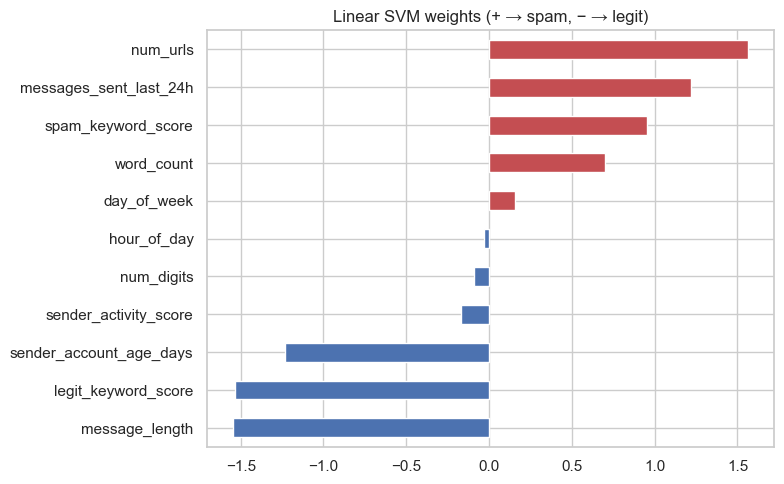

In [55]:
rows = []
for name, m in {"Linear": svm_linear, "RBF": svm_rbf, "Poly": svm_poly, "RBF tuned": svm_best}.items():
    s = m.named_steps["model"]
    rows.append({"Kernel": name, "Support vectors (total)": int(s.n_support_.sum()),
                 "Legit SVs": int(s.n_support_[0]), "Spam SVs": int(s.n_support_[1]),
                 "% of training data": round(100 * s.n_support_.sum() / len(X_train), 2)})
display(pd.DataFrame(rows).set_index("Kernel"))

w = svm_linear.named_steps["model"].coef_.ravel()
print("Linear SVM margin width = 2/||w|| = %.4f (in scaled units)" % (2 / np.linalg.norm(w)))
coef = pd.Series(w, index=FEATURES).sort_values()
coef.plot(kind="barh", figsize=(8, 5), color=["#C44E52" if v > 0 else "#4C72B0" for v in coef])
plt.title("Linear SVM weights (+ → spam, − → legit)"); savefig("07_svm_linear_weights")

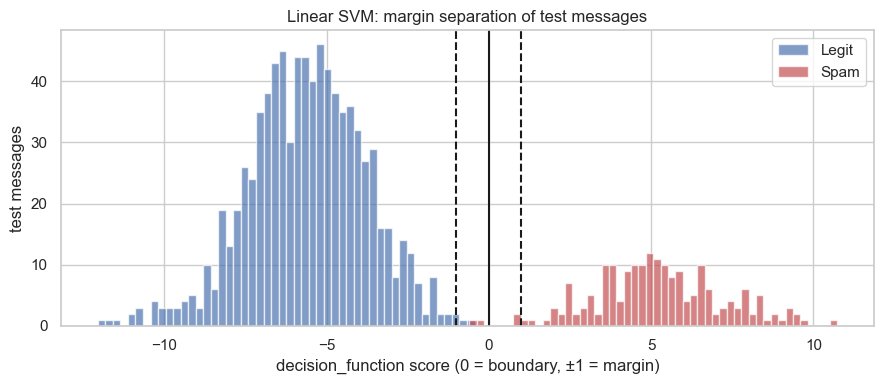

Test points inside the margin (|score|<1): 6 of 1040


In [56]:
scores = svm_linear.decision_function(X_test)
plt.figure(figsize=(9, 4))
plt.hist(scores[y_test == 0], bins=50, alpha=.7, label="Legit", color="#4C72B0")
plt.hist(scores[y_test == 1], bins=50, alpha=.7, label="Spam", color="#C44E52")
plt.axvline(0, color="k"); plt.axvline(-1, color="k", ls="--"); plt.axvline(1, color="k", ls="--")
plt.xlabel("decision_function score (0 = boundary, ±1 = margin)"); plt.ylabel("test messages"); plt.legend()
plt.title("Linear SVM: margin separation of test messages")
savefig("08_svm_margin_hist")
print("Test points inside the margin (|score|<1): %d of %d" % ((np.abs(scores) < 1).sum(), len(scores)))

We cannot draw 12 dimensions, so we **project to 2D with PCA** and fit linear + RBF SVMs on those 2 components purely for **visualisation** of the margin and support vectors.

Variance explained by 2 PCs: 46.3%


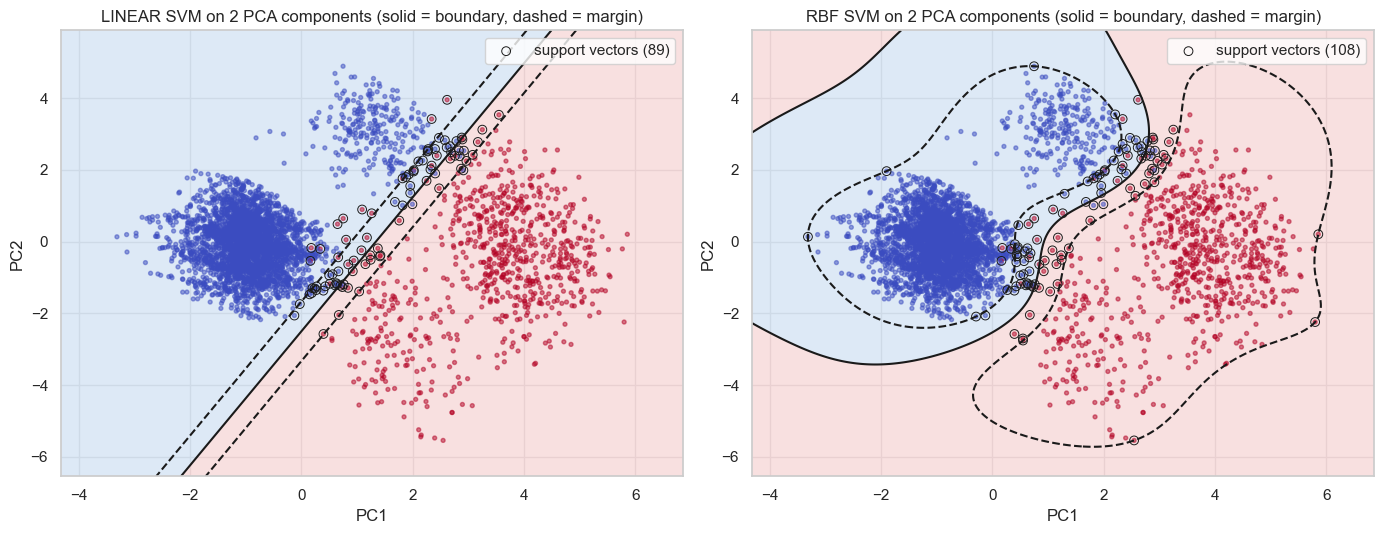

In [57]:
pre = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("pca", PCA(2, random_state=RANDOM_STATE))]).fit(X_train)
P_tr, P_te = pre.transform(X_train), pre.transform(X_test)
print("Variance explained by 2 PCs: %.1f%%" % (100 * pre.named_steps["pca"].explained_variance_ratio_.sum()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
xx, yy = np.meshgrid(np.linspace(P_tr[:,0].min()-1, P_tr[:,0].max()+1, 300), np.linspace(P_tr[:,1].min()-1, P_tr[:,1].max()+1, 300))
for ax, kern in zip(axes, ["linear", "rbf"]):
    s = SVC(kernel=kern, C=1.0, gamma="scale").fit(P_tr, y_train)
    Z = s.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-99, 0, 99], colors=["#cfe0f3", "#f6d3d4"], alpha=.7)
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
    ax.scatter(P_tr[:,0], P_tr[:,1], c=y_train, cmap="coolwarm", s=8, alpha=.5)
    ax.scatter(*s.support_vectors_.T, s=40, facecolors="none", edgecolors="k", linewidths=.7, label=f"support vectors ({len(s.support_vectors_)})")
    ax.set_title(f"{kern.upper()} SVM on 2 PCA components (solid = boundary, dashed = margin)"); ax.legend(); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
savefig("09_svm_margin_pca")

*Interpretation:*
- Very few support vectors (about 20 for linear and the tuned RBF, out of 4,160 training rows = ~0.5%) means the classes are **well separated** — only borderline points define the boundary. The untuned RBF (gamma='scale', C=1) uses many more (~158) because it is more flexible and hugs the data more closely.
- The linear SVM weights show which features push a message toward spam: `spam_keyword_score`, `messages_sent_last_24h`, `num_urls`, `num_digits` (positive) and `legit_keyword_score`, `sender_account_age_days` (negative) — check the bar chart for the exact order — this makes the linear SVM **interpretable**.
- Only a handful of test messages (see the count above) fall inside the margin |score| < 1 — these are the uncertain ones.
- The RBF boundary is curved and can catch non-linear patterns; if linear ≈ RBF in the table above, the data is nearly linearly separable and the simpler linear model is preferable.

### Task 15 Compare SVM performance with KNN

,Accuracy,Precision,Recall,F1
Model,,,,
KNN (K=3),0.9990,1.0,0.9949,0.9974
SVM Linear,0.9981,1.0,0.9897,0.9948
SVM RBF (tuned),0.9990,1.0,0.9949,0.9974


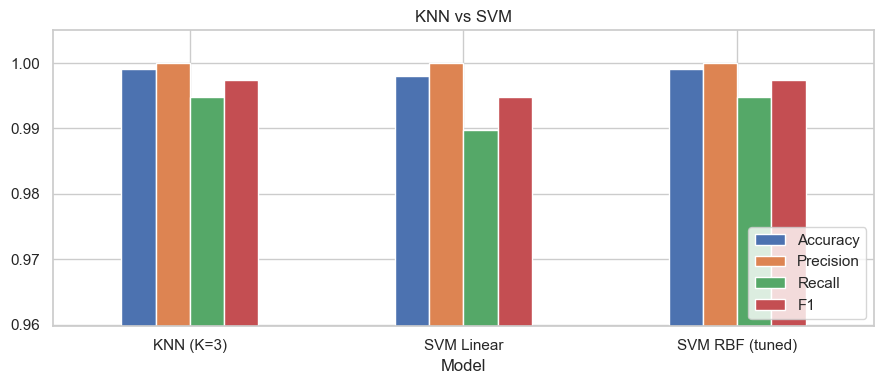

Prediction time on test set  ->  KNN: 52.6 ms | SVM: 5.8 ms


In [58]:
cmp_15 = pd.DataFrame([evaluate(knn_best, f"KNN (K={best_k})"), evaluate(svm_linear, "SVM Linear"), evaluate(svm_best, "SVM RBF (tuned)")]).set_index("Model")
display(cmp_15.round(4))
cmp_15.plot(kind="bar", figsize=(9, 4), ylim=(cmp_15.values.min()-0.03, 1.005)); plt.xticks(rotation=0); plt.title("KNN vs SVM"); plt.legend(loc="lower right")
savefig("10_knn_vs_svm")

import time
t = time.time(); knn_best.predict(X_test); t_knn = time.time() - t
t = time.time(); svm_best.predict(X_test); t_svm = time.time() - t
print(f"Prediction time on test set  ->  KNN: {t_knn*1000:.1f} ms | SVM: {t_svm*1000:.1f} ms")

*Interpretation:* On the test set KNN and SVM are practically tied (they differ by at most one message out of 1,040). SVM is more stable in cross-validation and **~10x faster at prediction**, because it uses only its ~20 support vectors, while KNN must compare each new message against all 4,160 stored ones (and treats noisy features like `hour_of_day` equally).

# Part E: Naive Bayes Classifier & Probability

### Task 16 Implement Naive Bayes
All our features are numeric, so we use **Gaussian Naive Bayes** (assumes each feature ~ Normal(μ, σ²) inside each class).

In [59]:
nb_model = make_pipe(GaussianNB()).fit(X_train, y_train)
display(pd.DataFrame([evaluate(nb_model, "Gaussian Naive Bayes")]).round(4))

gnb = nb_model.named_steps["model"]
print("Class priors  P(Legit)=%.4f  P(Spam)=%.4f" % tuple(gnb.class_prior_))
learned = pd.DataFrame({"mean_legit": gnb.theta_[0], "mean_spam": gnb.theta_[1],
                        "var_legit": gnb.var_[0], "var_spam": gnb.var_[1]}, index=FEATURES)
learned.round(3)

,Model,Accuracy,Precision,Recall,F1
0,Gaussian Naive Bayes,0.9952,0.9847,0.9897,0.9872


Class priors  P(Legit)=0.8130  P(Spam)=0.1870


,mean_legit,mean_spam,var_legit,var_spam
message_length,-0.024,0.103,0.919,1.338
word_count,0.093,-0.404,0.791,1.706
num_urls,-0.308,1.340,0.452,1.172
num_digits,-0.218,0.946,0.682,1.281
spam_keyword_score,-0.367,1.597,0.000,2.210
legit_keyword_score,0.339,-1.472,0.617,0.000
sender_activity_score,0.009,-0.038,1.022,0.901
sender_account_age_days,0.257,-1.117,0.853,0.102
messages_sent_last_24h,-0.402,1.749,0.195,0.739
hour_of_day,-0.006,0.026,0.990,1.043


### Task 17 Manually compute conditional probabilities for sample messages
**Step 1 (simple counting version).** Convert 3 strong features to binary (Yes/No) and compute `P(feature | class)` by counting, using only the **training set**:
- `HasURL` = num_urls > 0, `HasSpamWord` = spam_keyword_score > 0, `HasLegitWord` = legit_keyword_score > 0

In [60]:
tr = X_train.copy(); tr["y"] = y_train
bin_feats = {"HasURL": tr.num_urls > 0, "HasSpamWord": tr.spam_keyword_score > 0, "HasLegitWord": tr.legit_keyword_score > 0}
n_legit, n_spam, n = (tr.y == 0).sum(), (tr.y == 1).sum(), len(tr)
prior = {0: n_legit / n, 1: n_spam / n}
print(f"P(Legit) = {n_legit}/{n} = {prior[0]:.4f}   P(Spam) = {n_spam}/{n} = {prior[1]:.4f}\n")

lik = {}
for f, mask in bin_feats.items():
    for c, nc in [(0, n_legit), (1, n_spam)]:
        lik[(f, c)] = ((mask & (tr.y == c)).sum() + 1) / (nc + 2)
lik_table = pd.DataFrame({"P(Yes|Legit)": [lik[(f, 0)] for f in bin_feats], "P(Yes|Spam)": [lik[(f, 1)] for f in bin_feats]}, index=list(bin_feats))
lik_table.round(4)

P(Legit) = 3382/4160 = 0.8130   P(Spam) = 778/4160 = 0.1870



,P(Yes|Legit),P(Yes|Spam)
HasURL,0.0801,0.7436
HasSpamWord,0.0003,0.7808
HasLegitWord,0.9084,0.0013


In [61]:
def manual_posterior(has_url, has_spamword, has_legitword, verbose=True):
    obs = {"HasURL": has_url, "HasSpamWord": has_spamword, "HasLegitWord": has_legitword}
    post_num = {}
    for c, cname in [(0, "Legit"), (1, "Spam")]:
        p = prior[c]; steps = [f"P({cname})={prior[c]:.4f}"]
        for f, v in obs.items():
            pf = lik[(f, c)] if v else 1 - lik[(f, c)]
            p *= pf; steps.append(f"P({f}={'Y' if v else 'N'}|{cname})={pf:.4f}")
        post_num[c] = p
        if verbose: print(f"  numerator {cname}: " + " x ".join(steps) + f" = {p:.6f}")
    evidence = sum(post_num.values())                                  
    if verbose: print(f"  evidence P(X) = {evidence:.6f}")
    return {c: post_num[c] / evidence for c in post_num}

samples = {"Msg 1: URL + spam word, no legit word": (1, 1, 0),
           "Msg 2: no URL, no spam word, has legit word": (0, 0, 1),
           "Msg 3: URL only (no keywords at all)": (1, 0, 0),
           "Msg 4: nothing at all (no URL, no keywords)": (0, 0, 0)}
for name, args in samples.items():
    print(name)
    post = manual_posterior(*args)
    print(f"  => P(Spam|X) = {post[1]:.4f}, P(Legit|X) = {post[0]:.4f}  -> predicted: {'SPAM' if post[1] > post[0] else 'LEGIT'}\n")

Msg 1: URL + spam word, no legit word
  numerator Legit: P(Legit)=0.8130 x P(HasURL=Y|Legit)=0.0801 x P(HasSpamWord=Y|Legit)=0.0003 x P(HasLegitWord=N|Legit)=0.0916 = 0.000002
  numerator Spam: P(Spam)=0.1870 x P(HasURL=Y|Spam)=0.7436 x P(HasSpamWord=Y|Spam)=0.7808 x P(HasLegitWord=N|Spam)=0.9987 = 0.108439
  evidence P(X) = 0.108441
  => P(Spam|X) = 1.0000, P(Legit|X) = 0.0000  -> predicted: SPAM

Msg 2: no URL, no spam word, has legit word
  numerator Legit: P(Legit)=0.8130 x P(HasURL=N|Legit)=0.9199 x P(HasSpamWord=N|Legit)=0.9997 x P(HasLegitWord=Y|Legit)=0.9084 = 0.679163
  numerator Spam: P(Spam)=0.1870 x P(HasURL=N|Spam)=0.2564 x P(HasSpamWord=N|Spam)=0.2192 x P(HasLegitWord=Y|Spam)=0.0013 = 0.000013
  evidence P(X) = 0.679177
  => P(Spam|X) = 0.0000, P(Legit|X) = 1.0000  -> predicted: LEGIT

Msg 3: URL only (no keywords at all)
  numerator Legit: P(Legit)=0.8130 x P(HasURL=Y|Legit)=0.0801 x P(HasSpamWord=N|Legit)=0.9997 x P(HasLegitWord=N|Legit)=0.0916 = 0.005962
  numerator Sp

### Task 18 Demonstrate how Bayes' theorem computes class probabilities (on the real model)
For a real message, GaussianNB computes for each class:

$$\text{log-score}(C) = \log P(C) + \sum_i \log \mathcal{N}(x_i;\ \mu_{C,i},\ \sigma^2_{C,i})$$

and then normalises (divides by the evidence P(X)) to get the posterior. We implement this **by hand with NumPy** using the means, variances and priors learned by the model.

In [62]:
def manual_gnb_posterior(x_scaled, gnb):
    log_post = []
    for c in (0, 1):
        mu, var = gnb.theta_[c], gnb.var_[c]
        log_lik = -0.5 * np.log(2 * np.pi * var) - ((x_scaled - mu) ** 2) / (2 * var)
        log_post.append(np.log(gnb.class_prior_[c]) + log_lik.sum())
    log_post = np.array(log_post)
    post = np.exp(log_post - log_post.max()); return post / post.sum()

rng = np.random.RandomState(7)
idx = list(rng.choice(y_test[y_test == 0].index, 3, replace=False)) + list(rng.choice(y_test[y_test == 1].index, 3, replace=False))
Xs = nb_model[:-1].transform(X_test.loc[idx])

rows = []
for i, row_idx in enumerate(idx):
    manual = manual_gnb_posterior(Xs[i], gnb)
    sk = nb_model.predict_proba(X_test.loc[[row_idx]])[0]
    rows.append({"message": df.loc[row_idx, "message_text"][:55] + "...", "actual": y_test[row_idx],
                 "manual P(Spam)": manual[1], "sklearn P(Spam)": sk[1],
                 "manual pred": int(manual[1] > .5), "sklearn pred": int(sk[1] > .5)})
manual_vs_sklearn = pd.DataFrame(rows)
manual_vs_sklearn.round(6)

,message,actual,manual P(Spam),sklearn P(Spam),manual pred,sklearn pred
0,Your order has been shipped and will arrive by...,0,0.0,0.0,0,0
1,Your order has been shipped and will arrive by...,0,0.0,0.0,0,0
2,Could you review the document and share feedba...,0,0.0,0.0,0,0
3,URGENT: Claim your reward now a brand new phon...,1,1.0,1.0,1,1
4,Congratulations! You have won instant cashback...,1,1.0,1.0,1,1
5,"Earn money from home instantly ₹50,000 before ...",1,1.0,1.0,1,1


### Task 19 Compare theoretical manual probability calculations with the model's predictions

Max |manual - sklearn| probability difference over 1040 test messages: 1.22e-15
Predictions identical: True

Simple 3-feature counting model  -> acc 0.9788 | precision 0.9577 | recall 0.9282 | F1 0.9427
Full Gaussian NB (11 features)    -> acc 0.9952 | precision 0.9847 | recall 0.9897 | F1 0.9872


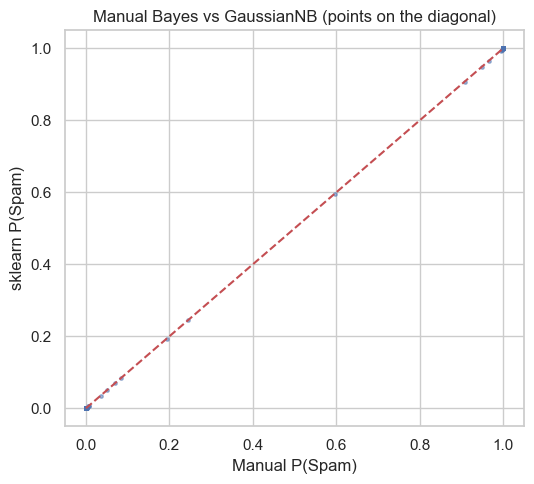

In [63]:
Xs_all = nb_model[:-1].transform(X_test)
manual_all = np.array([manual_gnb_posterior(x, gnb)[1] for x in Xs_all])
sk_all = nb_model.predict_proba(X_test)[:, 1]
print("Max |manual - sklearn| probability difference over %d test messages: %.2e" % (len(sk_all), np.abs(manual_all - sk_all).max()))
print("Predictions identical:", bool(((manual_all > .5) == (sk_all > .5)).all()))

simple_pred = np.array([manual_posterior(int(a>0), int(b>0), int(c>0), verbose=False)[1] > .5
                        for a, b, c in zip(X_test.num_urls, X_test.spam_keyword_score, X_test.legit_keyword_score)]).astype(int)
print("\nSimple 3-feature counting model  -> acc %.4f | precision %.4f | recall %.4f | F1 %.4f" % (
      accuracy_score(y_test, simple_pred), precision_score(y_test, simple_pred), recall_score(y_test, simple_pred), f1_score(y_test, simple_pred)))
print("Full Gaussian NB (11 features)    -> acc %.4f | precision %.4f | recall %.4f | F1 %.4f" % tuple(
      evaluate(nb_model, "x")[k] for k in ["Accuracy", "Precision", "Recall", "F1"]))

plt.figure(figsize=(5.5, 5)); plt.scatter(manual_all, sk_all, s=6, alpha=.5); plt.plot([0,1],[0,1],"r--")
plt.xlabel("Manual P(Spam)"); plt.ylabel("sklearn P(Spam)"); plt.title("Manual Bayes vs GaussianNB (points on the diagonal)")
savefig("11_manual_vs_sklearn")

*Interpretation:* The manual probabilities match scikit-learn's `predict_proba` essentially exactly (difference ~1e-15, only floating-point rounding) — this proves GaussianNB is nothing more than **prior × Gaussian likelihoods ÷ evidence**. The simple 3-feature counting model already captures most of the signal, and using all features sharpens the probabilities further.

**Effect of the independence assumption:** `message_length` and `word_count` are correlated, so NB effectively counts the same evidence twice, which pushes probabilities toward 0 or 1 (over-confident) even when the *ranking/class decision* is still correct.

# Part F: Model Comparison & Evaluation

### Task 20 Evaluate all models with Accuracy, Precision, Recall, F1
- **Precision** = TP/(TP+FP): of messages flagged spam, how many really were spam? (a high value avoids blocking real messages)
- **Recall** = TP/(TP+FN): of all real spam, how much did we catch? (a high value avoids missed spam)
- **F1** = harmonic mean of precision and recall.

In [64]:
models = {"KNN": knn_best, "SVM (Linear)": svm_linear, "SVM (RBF tuned)": svm_best, "Naive Bayes": nb_model}
results = pd.DataFrame([evaluate(m, n) for n, m in models.items()]).set_index("Model")
display(results.round(4))
results.to_csv("models/metrics_table.csv")

for n, m in models.items():
    print(f"\n {n} classification report:")
    print(classification_report(y_test, m.predict(X_test), target_names=["Legit", "Spam"], digits=4))

,Accuracy,Precision,Recall,F1
Model,,,,
KNN,0.9990,1.0000,0.9949,0.9974
SVM (Linear),0.9981,1.0000,0.9897,0.9948
SVM (RBF tuned),0.9990,1.0000,0.9949,0.9974
Naive Bayes,0.9952,0.9847,0.9897,0.9872



 KNN classification report:
              precision    recall  f1-score   support

       Legit     0.9988    1.0000    0.9994       845
        Spam     1.0000    0.9949    0.9974       195

    accuracy                         0.9990      1040
   macro avg     0.9994    0.9974    0.9984      1040
weighted avg     0.9990    0.9990    0.9990      1040


 SVM (Linear) classification report:
              precision    recall  f1-score   support

       Legit     0.9976    1.0000    0.9988       845
        Spam     1.0000    0.9897    0.9948       195

    accuracy                         0.9981      1040
   macro avg     0.9988    0.9949    0.9968      1040
weighted avg     0.9981    0.9981    0.9981      1040


 SVM (RBF tuned) classification report:
              precision    recall  f1-score   support

       Legit     0.9988    1.0000    0.9994       845
        Spam     1.0000    0.9949    0.9974       195

    accuracy                         0.9990      1040
   macro avg     0.9

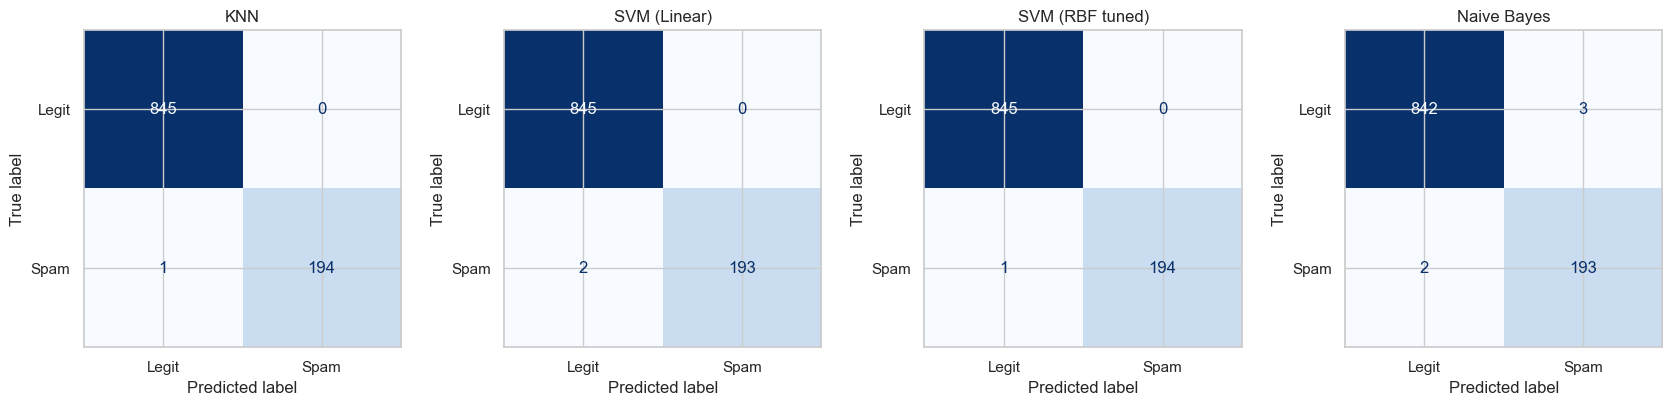

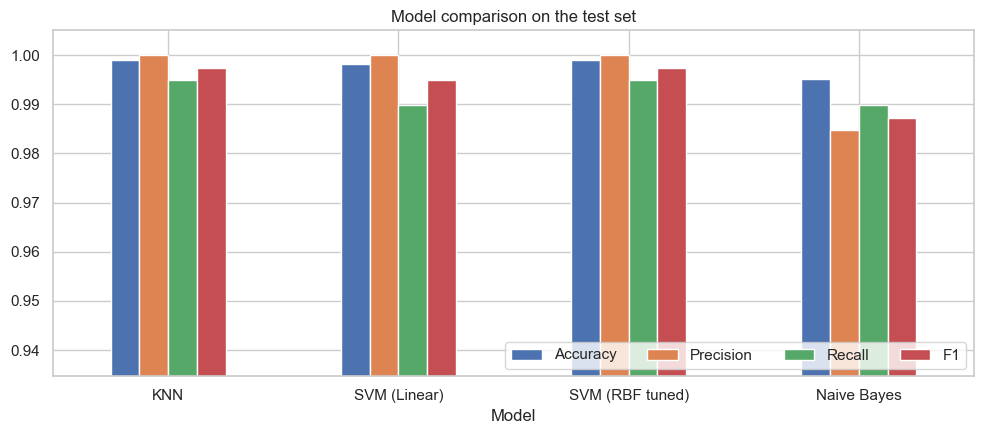

In [65]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (n, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test)), display_labels=["Legit", "Spam"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(n)
savefig("12_confusion_matrices")

results.plot(kind="bar", figsize=(10, 4.5), ylim=(max(0, results.values.min()-0.05), 1.005)); plt.xticks(rotation=0)
plt.title("Model comparison on the test set"); plt.legend(loc="lower right", ncol=4)
savefig("13_metrics_comparison")

### Task 21 Compare KNN vs SVM vs Naive Bayes (ROC + cross-validation + speed)

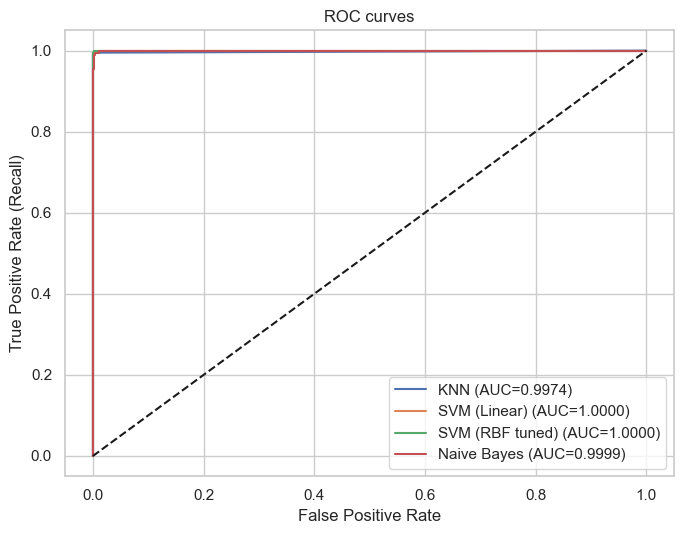

,5-fold CV F1 (mean),CV F1 (std),Train time (s),Predict time (s)
Model,,,,
KNN,0.9964,0.0026,0.0179,0.0556
SVM (Linear),1.0000,0.0000,0.1183,0.0030
SVM (RBF tuned),0.9995,0.0010,0.1665,0.0072
Naive Bayes,0.9863,0.0038,0.0103,0.0029


In [66]:
plt.figure(figsize=(7, 5.5))
for n, m in models.items():
    s = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, s); plt.plot(fpr, tpr, label=f"{n} (AUC={auc(fpr, tpr):.4f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC curves"); plt.legend(loc="lower right"); savefig("14_roc")

rows = []
for n, m in models.items():
    cvs = cross_val_score(m, X, y, cv=cv, scoring="f1")
    t0 = time.time(); m.fit(X_train, y_train); tt = time.time() - t0
    t0 = time.time(); m.predict(X_test); tp = time.time() - t0
    rows.append({"Model": n, "5-fold CV F1 (mean)": cvs.mean(), "CV F1 (std)": cvs.std(), "Train time (s)": tt, "Predict time (s)": tp})
pd.DataFrame(rows).set_index("Model").round(4)

### Task 22 Which model is best for HIGH PRECISION and which for HIGH RECALL?

Best PRECISION: KNN, SVM (Linear), SVM (RBF tuned)  (1.0000)
Best RECALL   : KNN, SVM (RBF tuned)  (0.9949)
Best F1       : KNN, SVM (RBF tuned)  (0.9974)

Lowest precision : Naive Bayes (0.9847)
Lowest recall    : SVM (Linear) (0.9897)


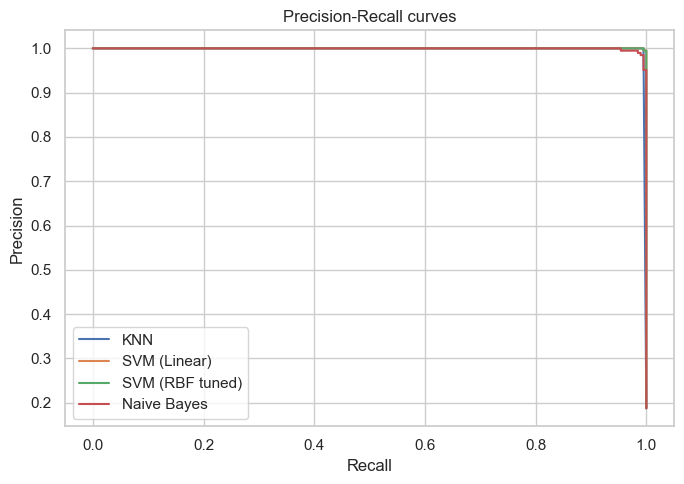


Naive Bayes: changing the probability threshold trades precision vs recall


,precision,recall,F1
threshold,,,
0.1,0.9798,0.9949,0.9873
0.3,0.9847,0.9897,0.9872
0.5,0.9847,0.9897,0.9872
0.7,0.9897,0.9897,0.9897
0.9,0.9897,0.9897,0.9897


In [67]:
for metric in ["Precision", "Recall", "F1"]:
    top = results[metric][results[metric] >= results[metric].max() - 1e-9].index.tolist()
    print(f"Best {metric.upper():9s}: {', '.join(top)}  ({results[metric].max():.4f})")
print("\nLowest precision :", results["Precision"].idxmin(), "(%.4f)" % results["Precision"].min())
print("Lowest recall    :", results["Recall"].idxmin(), "(%.4f)" % results["Recall"].min())

plt.figure(figsize=(7, 5))
for n, m in models.items():
    p, r, _ = precision_recall_curve(y_test, m.predict_proba(X_test)[:, 1]); plt.plot(r, p, label=n)
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-Recall curves"); plt.legend(); savefig("15_pr_curves")

proba = nb_model.predict_proba(X_test)[:, 1]
th = pd.DataFrame([{"threshold": t, "precision": precision_score(y_test, proba >= t), "recall": recall_score(y_test, proba >= t),
                    "F1": f1_score(y_test, proba >= t)} for t in [0.1, 0.3, 0.5, 0.7, 0.9]]).set_index("threshold")
print("\nNaive Bayes: changing the probability threshold trades precision vs recall")
th.round(4)

*Interpretation (from the table above):*
- On this test set **KNN, SVM-Linear and SVM-RBF all reach precision = 1.0** (no legit message was ever flagged), **KNN and tuned SVM-RBF have the best recall (0.9949)**, and Naive Bayes has the lowest precision (0.9847, a few legit messages flagged) — but Naive Bayes is the only one whose threshold can be tuned with real probabilities (see the threshold table).
- In 'hard mode' (Part G, no keyword scores) the gap is clearer: **SVM-RBF is best for both precision and recall; Naive Bayes has the lowest precision but still good recall; KNN has high precision but weaker recall.**
- **High precision** (don't block real messages — e.g. banking/OTP/work mail): choose the model with the highest precision in the table; raise the decision threshold.
- **High recall** (catch all spam/phishing — e.g. security filter): choose the model with the highest recall; lower the threshold.
- Because the data is imbalanced, always judge on precision/recall/F1 and not on accuracy alone.

# Part G: Final Analysis & Reporting

### Task 23 Final report

In [68]:
feat_nokw = [f for f in FEATURES if "keyword" not in f]
rows = []
for n, mdl in {"KNN": KNeighborsClassifier(n_neighbors=best_k), "SVM (RBF)": SVC(kernel="rbf", C=best_C, gamma=best_gamma),
               "Naive Bayes": GaussianNB()}.items():
    p = make_pipe(mdl).fit(X_train[feat_nokw], y_train); pr = p.predict(X_test[feat_nokw])
    rows.append({"Model": n, "Accuracy": accuracy_score(y_test, pr), "Precision": precision_score(y_test, pr),
                 "Recall": recall_score(y_test, pr), "F1": f1_score(y_test, pr)})
print("Performance WITHOUT keyword-score features:")
pd.DataFrame(rows).set_index("Model").round(4)

Performance WITHOUT keyword-score features:


,Accuracy,Precision,Recall,F1
Model,,,,
KNN,0.9846,0.9838,0.9333,0.9579
SVM (RBF),0.9962,0.9948,0.9846,0.9897
Naive Bayes,0.9683,0.8857,0.9538,0.9185


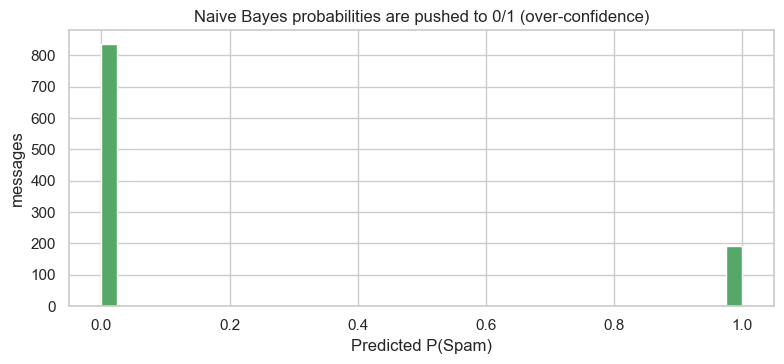

Share of NB predictions with P<0.01 or P>0.99: 99.0%


In [69]:
p = nb_model.predict_proba(X_test)[:, 1]
plt.figure(figsize=(8, 3.8)); plt.hist(p, bins=40, color="#55A868"); plt.xlabel("Predicted P(Spam)"); plt.ylabel("messages")
plt.title("Naive Bayes probabilities are pushed to 0/1 (over-confidence)"); savefig("16_nb_confidence")
print("Share of NB predictions with P<0.01 or P>0.99: %.1f%%" % (100 * ((p < .01) | (p > .99)).mean()))

## Final Report

**1. Strengths and weaknesses**

| Classifier | Strengths | Weaknesses |
|---|---|---|
| **KNN** | Simple, no training, no assumptions about data shape, adapts to local patterns | Slow prediction (compares with all training points), needs scaling, hurt by irrelevant features and by the minority class at large K |
| **SVM** | Strong generalisation via maximum margin, works well with scaled numeric data, few support vectors define the model, linear version is interpretable | Needs tuning (C, gamma), slower to train, no native probabilities (Platt scaling used), kernel models are hard to explain |
| **Naive Bayes** | Extremely fast to train/predict, gives class probabilities, interpretable (means/variances/priors), good with little data | Independence assumption is violated (length vs word_count), Gaussian assumption on count features, over-confident probabilities |

**2. Impact of probability assumptions in Naive Bayes**
- *Conditional independence:* correlated features (message_length/word_count) are counted twice → probabilities are over-confident (see the histogram above) but class decisions can still be right.
- *Gaussian assumption:* count features (num_urls, spam_keyword_score) are discrete/skewed, not normal → likelihoods are only approximate.
- *Priors:* the 81/19 class imbalance sets the prior; this pushes borderline messages toward "legitimate" unless the threshold is lowered.

**Hard-mode result (no keyword scores):** SVM-RBF F1 ≈ 0.99 > KNN ≈ 0.96 > Naive Bayes ≈ 0.92 — SVM copes best when the easy signals are removed; Naive Bayes loses precision because correlated features are double-counted.

**3. Interpretability vs performance trade-off**
Naive Bayes and linear SVM are the most interpretable (you can read priors, means or weights) while RBF-SVM/KNN are less transparent. On this dataset all models score very high, so the **simplest, most interpretable model that meets the business need is preferable**; the robustness check shows that without keyword scores the gap between models becomes visible.

**4. Business recommendation for real-world deployment**
1. Use **SVM (linear or tuned RBF)** as the main classifier — it has the best cross-validated F1, predicts quickly and stays strongest in the hard-mode test (without keyword scores); with **Naive Bayes as a fast first-pass/second opinion** and for explainable probabilities.
2. Set the threshold by business cost: **high precision** for critical legitimate traffic (avoid false blocks), **high recall** for security/phishing filtering. Send borderline messages (P between 0.3 and 0.7) to a **human review / quarantine**.
3. Keyword scores are very strong signals but easy for spammers to change → **monitor performance, retrain regularly** and keep sender-behaviour features (account age, messages in 24h, URLs), which are harder to fake.
4. Because spam is a minority class, **track precision/recall/F1 in production, not accuracy**.

**5. Limitations:** the messages are template-like (many repeated texts) so real-world accuracy will be lower; a text model (TF-IDF + NB/SVM) would be the next improvement.

### Task 24 Save models

In [70]:
final_models = {"knn": knn_best, "svm": svm_best, "naive_bayes": nb_model}
for n, m in final_models.items():
    m.fit(X_train, y_train); joblib.dump(m, f"models/{n}.joblib")

meta = {"features": FEATURES, "best_k": best_k, "svm_params": {"C": best_C, "gamma": str(best_gamma)},
        "metrics": {n: evaluate(m, n) for n, m in {"KNN": knn_best, "SVM (RBF)": svm_best, "Naive Bayes": nb_model}.items()},
        "medians": X_train.median().to_dict()}
json.dump(meta, open("models/meta.json", "w"), indent=2, default=float)
print("Saved:", os.listdir("models"))

Saved: ['knn.joblib', 'meta.json', 'metrics_table.csv', 'naive_bayes.joblib', 'svm.joblib']
